In [12]:
%pip install pvlib pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 10.5 MB/s eta 0:00:00m eta 0:00:010:0101
Note: you may need to restart the kernel to use updated packages.


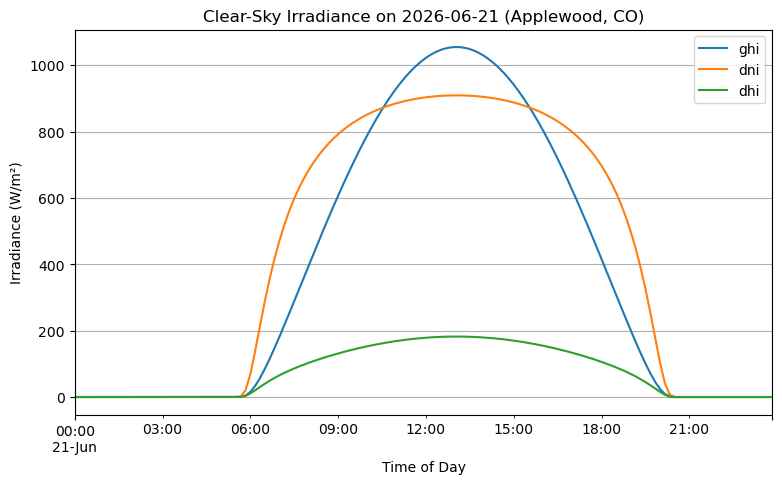

In [13]:
import pandas as pd
import pvlib
from pvlib.location import Location
import matplotlib.pyplot as plt

# 1. Define your location (e.g., Applewood, CO)
latitude = 39.747
longitude = -105.151
altitude = 1750  # meters
tz = 'America/Denver'
site = Location(latitude, longitude, tz=tz, altitude=altitude, name='Applewood, CO')

# 2. Pick your specific date (e.g., Summer Solstice 2026)
specific_day = '2026-06-21'
times = pd.date_range(start=f'{specific_day} 00:00', 
                      end=f'{specific_day} 23:50', 
                      freq='10min', 
                      tz=tz)

# 3. Calculate clear-sky GHI, DNI, and DHI
irradiance = site.get_clearsky(times)

# 4. Plot the diurnal profile
irradiance.plot(figsize=(9, 5))
plt.title(f"Clear-Sky Irradiance on {specific_day} (Applewood, CO)")
plt.ylabel("Irradiance (W/m²)")
plt.xlabel("Time of Day")
plt.grid(True)
plt.show()


In [ ]:
# Faradaic Efficiency (%) for each product at different light intensities
# [H2, CO, CH4, C2H4, Formate, Acetate, Ethanol]
fe_data = {
    0.1: [42, 2.5, 2.5, 9, 6, 2, 0],    # FEs at 0.1 Sun
    0.5: [64, 4, 0, 11, 4.5, 4.5, 3],  # FEs at 0.5 Sun
    1.0: [55, 6, 2, 4.5, 2.5, 2, 2.5]  # FEs at 1 Sun
}


--- Total Daily Product Generation (per m²) ---
CO         882775.58
CH4         61529.79
C2H4       185559.59
Formate    550746.29
Acetate    114300.71
Ethanol     70315.16
dtype: float64


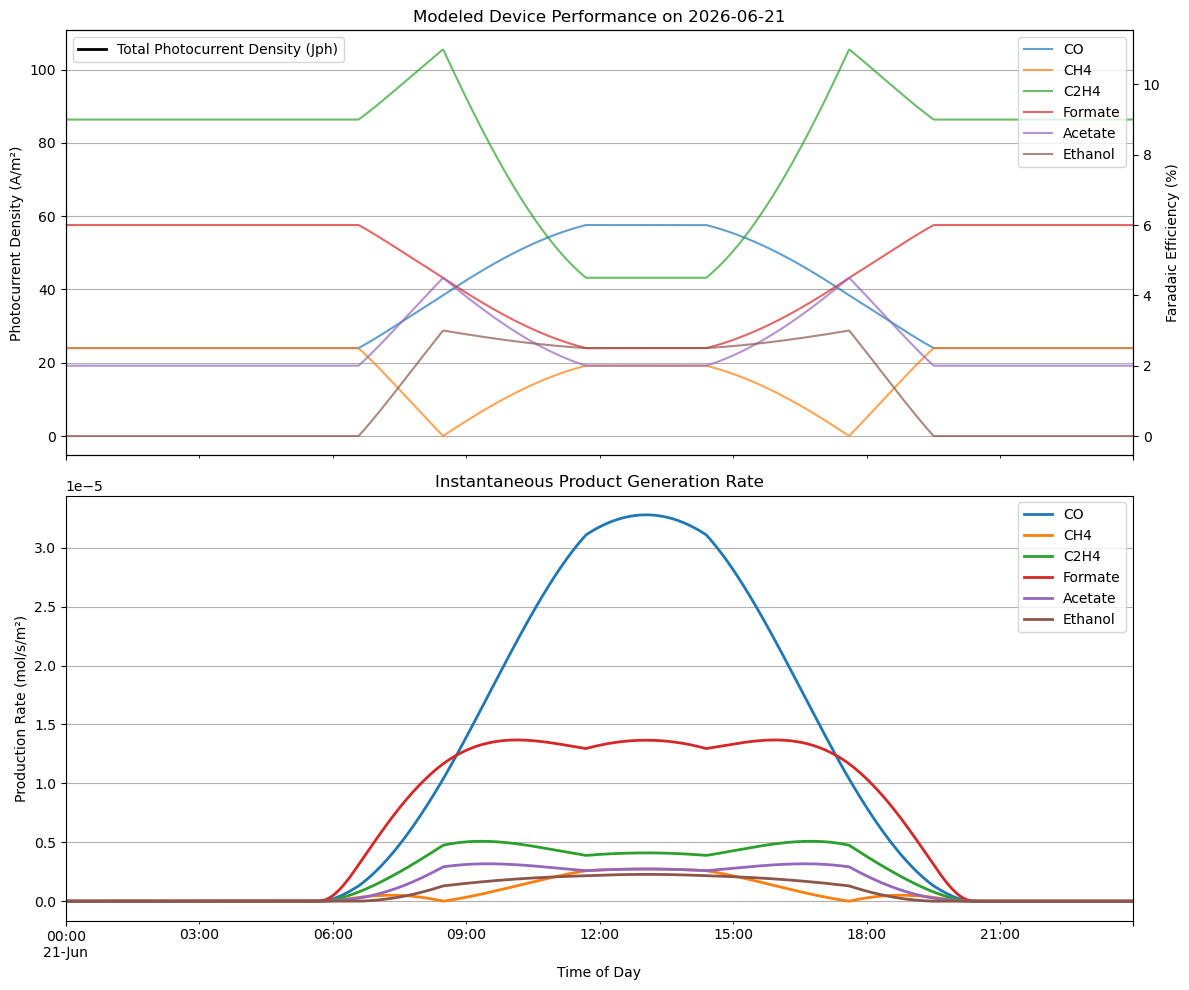

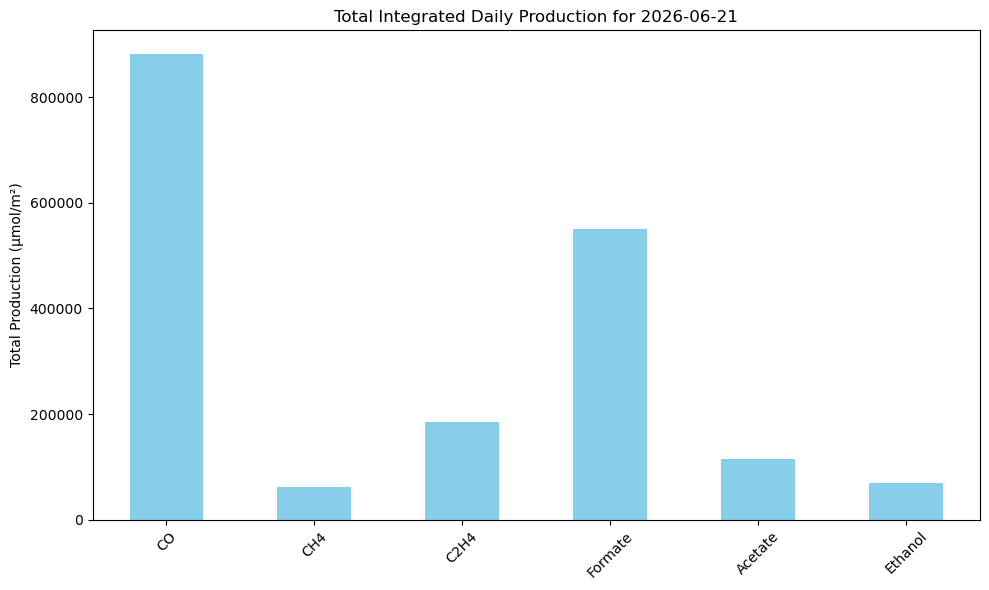

In [16]:
import pandas as pd
import numpy as np
import pvlib
from pvlib.location import Location
import matplotlib.pyplot as plt

# --- Step 1: Define Experimental Data ---

# Faradaic Efficiency (%) for each product at different light intensities
# Extracted from the user's bar chart.
# Products: [H2, CO, CH4, C2H4, Formate, Acetate, Ethanol]
fe_data = {
    0.1: [ 2.5, 2.5, 9, 6, 2, 0],    # FEs at 0.1 Sun
    0.5: [4, 0, 11, 4.5, 4.5, 3],  # FEs at 0.5 Sun
    1.0: [ 6, 2, 4.5, 2.5, 2, 2.5]   # FEs at 1 Sun
}
products = ['CO', 'CH4', 'C2H4', 'Formate', 'Acetate', 'Ethanol']
electrons_per_product = { 'CO': 2, 'CH4': 8, 'C2H4': 12, 'Formate': 2, 'Acetate': 8, 'Ethanol': 12}
faraday_constant = 96485  # C/mol

# Create a DataFrame for easy interpolation
fe_df = pd.DataFrame(fe_data, index=products).T
fe_df.index.name = 'Sun'

# --- Step 2: Define Device and Location Parameters ---

# Assume a photocurrent density at 1 Sun (1000 W/m^2).
# This is a critical assumption. Let's use 10 mA/cm^2, which is 100 A/m^2.
J_ph_at_1_sun = 100  # A/m^2

# Location from the previous irradiance plot
latitude = 39.747
longitude = -105.151
altitude = 1750
tz = 'America/Denver'
site = Location(latitude, longitude, tz=tz, altitude=altitude)
specific_day = '2026-06-21'

# --- Step 3: Model Irradiance and Photocurrent ---

# Generate time series for the day (1-minute intervals for accuracy)
times = pd.date_range(start=f'{specific_day} 00:00', end=f'{specific_day} 23:59', freq='1min', tz=tz)
irradiance = site.get_clearsky(times)
ghi = irradiance['ghi']

# Calculate sun level and photocurrent density over time
sun_levels = ghi / 1000.0
J_ph_t = J_ph_at_1_sun * sun_levels

# --- Step 4: Calculate Product Generation Rate (Corrected) ---

# Interpolate FE for each product at each time step based on the sun level
# The result, fe_over_time, will have a DatetimeIndex matching sun_levels
fe_over_time = pd.DataFrame(index=sun_levels.index, columns=products)
for product in products:
    # For each product, interpolate its FE against the sun levels over time
    fe_over_time[product] = np.interp(sun_levels, fe_df.index, fe_df[product])

# Now the multiplication works because both DataFrames share the same DatetimeIndex
partial_J_t = fe_over_time.multiply(J_ph_t, axis='index') / 100.0

# Calculate the rate of product formation in mol/s/m^2
production_rate = pd.DataFrame(index=partial_J_t.index)
for product in products:
    n = electrons_per_product[product]
    production_rate[product] = partial_J_t[product] / (n * faraday_constant)

# --- Step 5: Integrate to Find Total Daily Production ---

# The time step is 60 seconds
time_step_seconds = 60
total_production_mol_m2 = production_rate.sum() * time_step_seconds

# Convert moles to a more intuitive unit like micromoles (umol)
total_production_umol_m2 = total_production_mol_m2 * 1e6

print("--- Total Daily Product Generation (per m²) ---")
print(total_production_umol_m2.round(2))

# --- Step 6: Visualize the Results ---

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

# Plot 1: Photocurrent and FE
ax1.plot(J_ph_t.index, J_ph_t, label='Total Photocurrent Density (Jph)', color='black', lw=2)
ax1_twin = ax1.twinx()
fe_over_time.plot(ax=ax1_twin, alpha=0.7)
ax1.set_ylabel('Photocurrent Density (A/m²)')
ax1_twin.set_ylabel('Faradaic Efficiency (%)')
ax1.set_title(f'Modeled Device Performance on {specific_day}')
ax1.grid(True)
ax1.legend(loc='upper left')
ax1_twin.legend(loc='upper right')

# Plot 2: Production Rate
production_rate.plot(ax=ax2, lw=2)
ax2.set_ylabel('Production Rate (mol/s/m²)')
ax2.set_xlabel('Time of Day')
ax2.set_title('Instantaneous Product Generation Rate')
ax2.grid(True)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

# Create a summary bar chart
fig_bar, ax_bar = plt.subplots(figsize=(10, 6))
total_production_umol_m2.plot(kind='bar', ax=ax_bar, color='skyblue')
ax_bar.set_ylabel('Total Production (μmol/m²)')
ax_bar.set_title(f'Total Integrated Daily Production for {specific_day}')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



In [18]:
import pandas as pd
import numpy as np
import pvlib
from pvlib.location import Location
import matplotlib.pyplot as plt

# --- Step 1: Define Experimental FE as Percentages ---
products = [ 'CO', 'CH4', 'C2H4', 'Formate', 'Acetate', 'Ethanol']
electrons_per_product = {'CO': 2, 'CH4': 8, 'C2H4': 12, 'Formate': 2, 'Acetate': 8, 'Ethanol': 12}
faraday_constant = 96485  # C/mol

# FEs mapped as pure percentages directly from your bar chart
fe_data = {
    0.1: [2.5, 2.5, 9.0, 6.0, 2.0, 0.0],   # % FE at 0.1 Sun
    0.5: [ 4.0, 0.0, 11.0, 4.5, 4.5, 3.0],  # % FE at 0.5 Sun
    1.0: [ 6.0, 2.0, 4.5, 2.5, 2.0, 2.5]    # % FE at 1.0 Sun
}

fe_df = pd.DataFrame(fe_data, index=products).T
fe_df.index.name = 'Sun'

# --- Step 2: Define Location & Peak Photocurrent ---
# ADJUST THIS value to match your actual measured peak current at 1 Sun!
J_ph_at_1_sun = 100  # A/m² (equivalent to 10 mA/cm²)

latitude, longitude, altitude = 39.747, -105.151, 1750
tz = 'America/Denver'
site = Location(latitude, longitude, tz=tz, altitude=altitude)
specific_day = '2026-06-21'

# --- Step 3: Diurnal Solar Sweep ---
times = pd.date_range(start=f'{specific_day} 00:00', end=f'{specific_day} 23:59', freq='1min', tz=tz)
ghi = site.get_clearsky(times)['ghi']
sun_levels = ghi / 1000.0
J_ph_t = J_ph_at_1_sun * sun_levels

# --- Step 4: Interpolate FE as Percentages (%) ---
fe_over_time = pd.DataFrame(index=sun_levels.index, columns=products)
for product in products:
    # Interpolating directly on the 0-100% scale
    fe_over_time[product] = np.interp(sun_levels, fe_df.index, fe_df[product])

# --- Step 5: Convert to Product Yields ---
# We divide by 100 *only* inside the chemical rate equation to transition from % to fraction
production_rate = pd.DataFrame(index=fe_over_time.index)
for product in products:
    n = electrons_per_product[product]
    # FE (%) is converted to decimal (fe/100) here to solve for real moles
    partial_J_t = (fe_over_time[product] / 100.0) * J_ph_t 
    production_rate[product] = partial_J_t / (n * faraday_constant)

# Integrate over 60-second intervals to find total daily micromoles per m²
total_production_umol_m2 = production_rate.sum() * 60 * 1e6

print("--- Total Daily Product Generation (μmol/m²) ---")
print(total_production_umol_m2.round(2))

--- Total Daily Product Generation (μmol/m²) ---
CO         882775.58
CH4         61529.79
C2H4       185559.59
Formate    550746.29
Acetate    114300.71
Ethanol     70315.16
dtype: float64


--- Total Daily Product Generation based on your Experimental Data (μmol/m²) ---
CO         600580.17
CH4         70540.94
C2H4       101434.30
Formate    701415.44
Acetate     74637.33
Ethanol     79554.40
dtype: float64


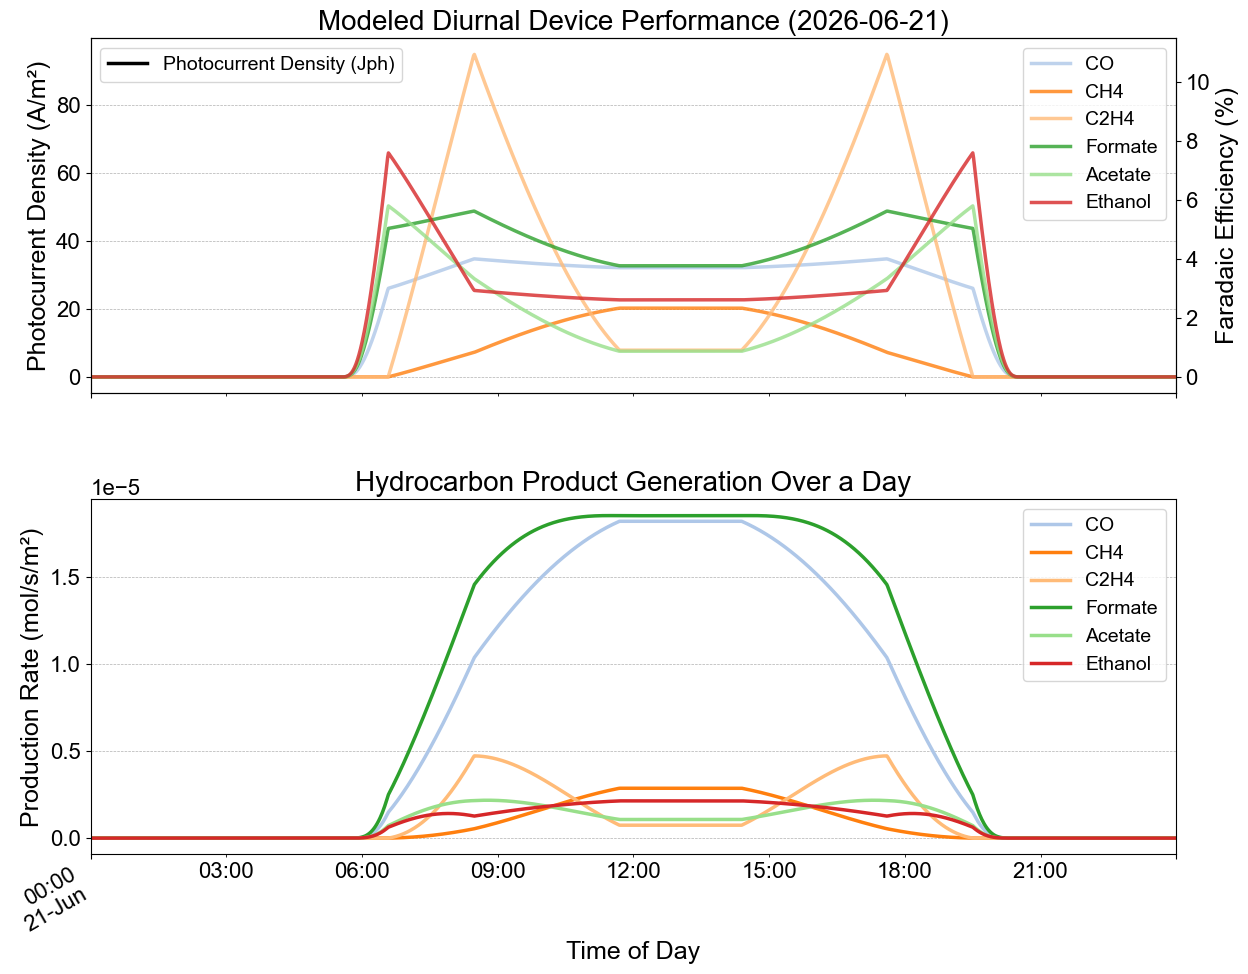

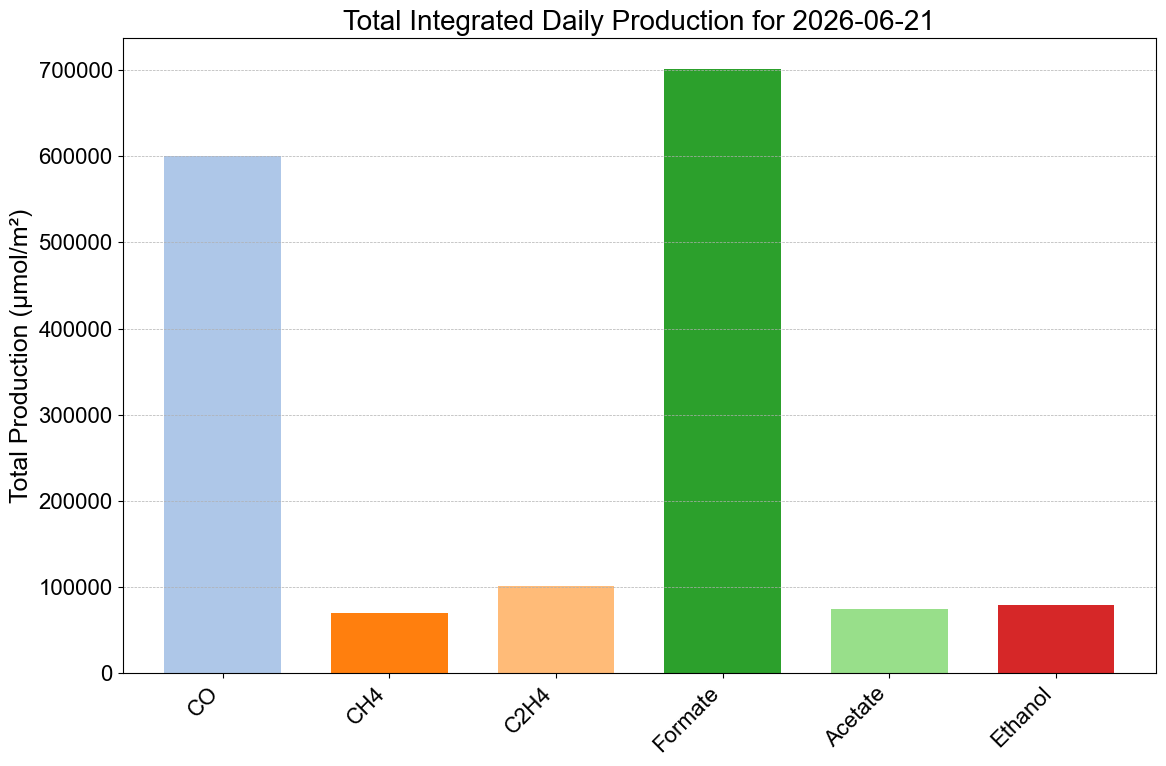

In [25]:
import pandas as pd
import numpy as np
import pvlib
from pvlib.location import Location
import matplotlib.pyplot as plt

# --- Step 0: Set Plotting Style for Publication Quality ---
try:
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': 'Arial',
        'font.size': 18,
        'axes.labelsize': 18,
        'axes.titlesize': 20,
        'xtick.labelsize': 16,
        'ytick.labelsize': 16,
        'legend.fontsize': 14,
        'figure.titlesize': 22
    })
except Exception:
    print("Arial font not found, using default sans-serif.")


# --- Step 1: Define All Experimental Data ---

# A. Faradaic Efficiency (%) from your bar chart
# Includes the zero-point anchor for nighttime.
fe_data = {
    0.0: [ 0, 0, 0, 0, 0, 0],         # FE is 0% at 0 Sun
    0.1: [ 3, 0, 0, 5.03, 5.8, 7.6],    # FEs at 0.1 Sun
    0.5: [4, 0.83, 10.95, 5.62, 3.33, 2.93],  # FEs at 0.5 Sun
    1.0: [3.7, 2.33, 0.905, 3.765, 0.87, 2.61]   # FEs at 1 Sun

}


products = ['CO', 'CH4', 'C2H4', 'Formate', 'Acetate', 'Ethanol']
color_map = {
    'CO': '#aec7e8',
    'CH4': '#ff7f0e',
    'C2H4': '#ffbb78',
    'Formate': '#2ca02c',
    'Acetate': '#98df8a',
    'Ethanol': '#d62728'
}


# B. Photocurrent Density (J_ph) from your measurements
# We convert mA/cm^2 to A/m^2 by multiplying by 10.
# We use the absolute value for production calculations.
j_ph_data = {
    0.0: 0.0,                   # 0 mA/cm^2 at 0 Sun
    0.1: 0.95 * 10,             # 9.5 A/m^2 at 0.1 Sun
    0.5: 5.0 * 10,              # 50 A/m^2 at 0.5 Sun
    1.0: 9.5 * 10               # 95 A/m^2 at 1 Sun
}
j_ph_df = pd.DataFrame.from_dict(j_ph_data, orient='index', columns=['J_ph'])
j_ph_df.index.name = 'Sun'


# C. Electrochemical Constants
electrons_per_product = {'CO': 2, 'CH4': 8, 'C2H4': 12, 'Formate': 2, 'Acetate': 8, 'Ethanol': 12}
faraday_constant = 96485  # C/mol

# Create a DataFrame for FE interpolation
fe_df = pd.DataFrame(fe_data, index=products).T
fe_df.index.name = 'Sun'

# --- Step 2: Define Location and Solar Parameters ---
latitude = 39.747
longitude = -105.151
altitude = 1750
tz = 'America/Denver'
site = Location(latitude, longitude, tz=tz, altitude=altitude)
specific_day = '2026-06-21'

# --- Step 3: Model Irradiance and Interpolate Photocurrent ---

# Generate time series for the day
times = pd.date_range(start=f'{specific_day} 00:00', end=f'{specific_day} 23:59', freq='1min', tz=tz)
ghi = site.get_clearsky(times)['ghi']
sun_levels = ghi / 1000.0

# **UPDATED**: Interpolate photocurrent from your experimental data
J_ph_t = np.interp(sun_levels, j_ph_df.index, j_ph_df['J_ph'])
J_ph_t = pd.Series(J_ph_t, index=times) # Convert back to a pandas Series with time index

# --- Step 4: Calculate Product Generation Rate ---

# Interpolate FE based on the sun levels throughout the day
fe_over_time = pd.DataFrame(index=sun_levels.index, columns=products)
for product in products:
    fe_over_time[product] = np.interp(sun_levels, fe_df.index, fe_df[product])

# Calculate partial current for each product
partial_J_t = fe_over_time.multiply(J_ph_t, axis='index') / 100.0

# Calculate the rate of product formation in mol/s/m^2
production_rate = pd.DataFrame(index=partial_J_t.index)
for product in products:
    n = electrons_per_product[product]
    production_rate[product] = partial_J_t[product] / (n * faraday_constant)


# --- Step 5: Integrate to Find Total Daily Production ---
time_step_seconds = 60
total_production_umol_m2 = (production_rate.sum() * time_step_seconds) * 1e6

print("--- Total Daily Product Generation based on your Experimental Data (μmol/m²) ---")
print(total_production_umol_m2.round(2))


# --- Step 6: Visualize the Results (with Enhanced Aesthetics) ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 12), sharex=True)
plt.subplots_adjust(hspace=0.3)

# Plot 1: Photocurrent and FE
ax1.plot(J_ph_t.index, J_ph_t, label='Photocurrent Density (Jph)', color='black', lw=2.5)
ax1_twin = ax1.twinx()
fe_over_time.plot(ax=ax1_twin, alpha=0.8, lw=2.5, color=[color_map[p] for p in products])
ax1.set_ylabel('Photocurrent Density (A/m²)')
ax1_twin.set_ylabel('Faradaic Efficiency (%)')
ax1.set_title(f'Modeled Diurnal Device Performance ({specific_day})')
ax1.grid(True, which='major', linestyle='--', linewidth=0.5)
ax1.legend(loc='upper left')
ax1_twin.legend(loc='upper right')

# Plot 2: Production Rate
production_rate.plot(ax=ax2, lw=2.5, color=[color_map[p] for p in products])
ax2.set_ylabel('Production Rate (mol/s/m²)')
ax2.set_xlabel('Time of Day')
ax2.set_title('Hydrocarbon Product Generation Over a Day')
ax2.grid(True, which='major', linestyle='--', linewidth=0.5)
ax2.legend(loc='upper right')
fig.autofmt_xdate() # Improve date formatting
plt.show()

# Create a summary bar chart
fig_bar, ax_bar = plt.subplots(figsize=(12, 8))
total_production_umol_m2.plot(kind='bar', ax=ax_bar, color=[color_map[p] for p in total_production_umol_m2.index], width=0.7)
ax_bar.set_ylabel('Total Production (μmol/m²)')
ax_bar.set_title(f'Total Integrated Daily Production for {specific_day}')
ax_bar.grid(axis='y', linestyle='--', linewidth=0.5)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()